In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from improc.io import parse_collection, DCAccessor
import inter_view.color

DCAccessor.register()

In [8]:
import luigi 

# luigi.configuration.add_config_path('../config.cfg')
luigi.configuration.get_config().get()

TypeError: get() missing 2 required positional arguments: 'section' and 'option'

In [11]:
config = luigi.configuration.get_config()

{s:dict(config.items(s)) for s in config.sections()}

{}

In [2]:
df = pd.read_hdf('/tungstenfs/scratch/gliberal/Users/ortiraph/datasets/ISIT/2D_mip_org_seg/training_collection.h5', 'dc')

('crop001_day06_201102JD003AAB_201031_211848_E05_T0029F001L29A03Z01C01_roi_638_3450_3053_5932', '20X_T144_crowded-area')


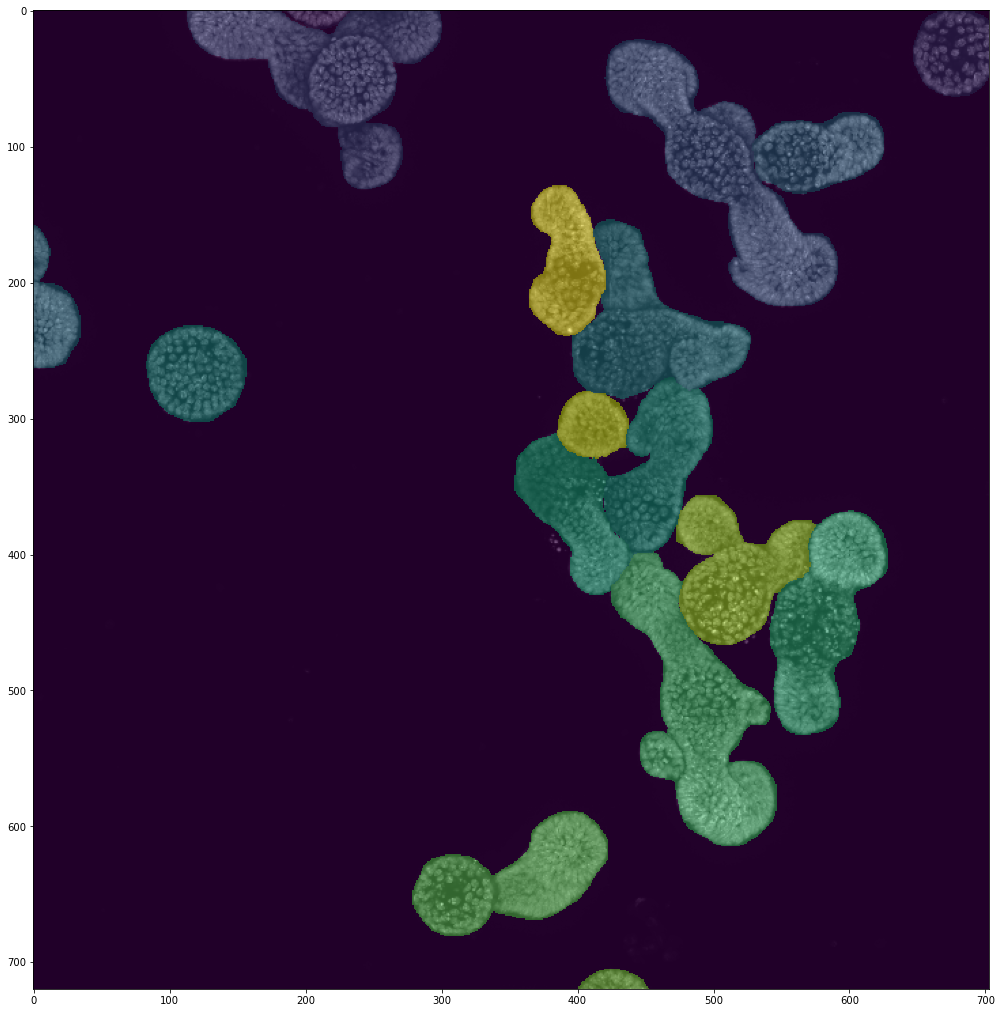

In [3]:
step = 4

for idx,subdf in df.dc[:,:,'20X_T144_crowded-area','crop001_day06_201102JD003AAB_201031_211848_E05_T0029F001L29A03Z01C01_roi_638_3450_3053_5932'].groupby(['fname', 'subset']):
    annot, raw = subdf.dc.read()
    print(idx)
    plt.figure(figsize=(18,18))
    plt.imshow(raw[::step,::step], cmap='Greys_r')
    plt.imshow(annot[::step,::step], interpolation='nearest', alpha=0.5)
    plt.show()
    
#     break

In [4]:
import tensorflow as tf

physical_devices = tf.config.experimental.list_physical_devices('GPU')
assert len(physical_devices) > 0, "Not enough GPU hardware devices available"
tf.config.experimental.set_memory_growth(physical_devices[0], True)


model_path = '/tungstenfs/scratch/gliberal/Users/ortiraph/datasets/ISIT/2D_mip_org_seg/training_output/RDCNet-F8-DC16-G4-DR1-2-4-8-GC32-S6-D0.1_20210326_inference'
model = tf.saved_model.load(model_path)

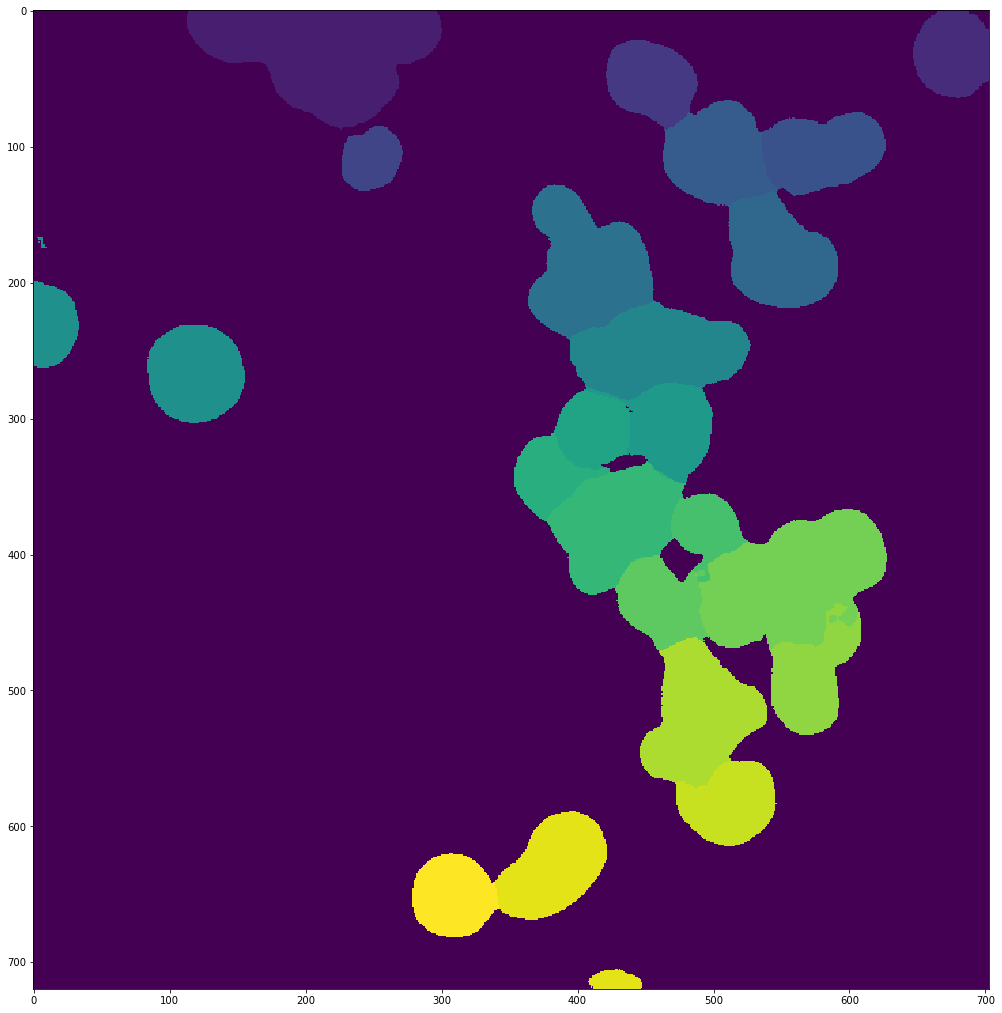

In [5]:
# raw = (np.random.rand(1485*2,1760*2)>0.5).astype(np.uint16)

predict_fn = model.signatures['pred_instance']
pred = predict_fn(tf.convert_to_tensor(raw[::4,::4]))['labels']
# pred = predict_fn(tf.convert_to_tensor(raw))['labels']


plt.figure(figsize=(18,18))
plt.imshow(pred, interpolation='nearest')
plt.show()

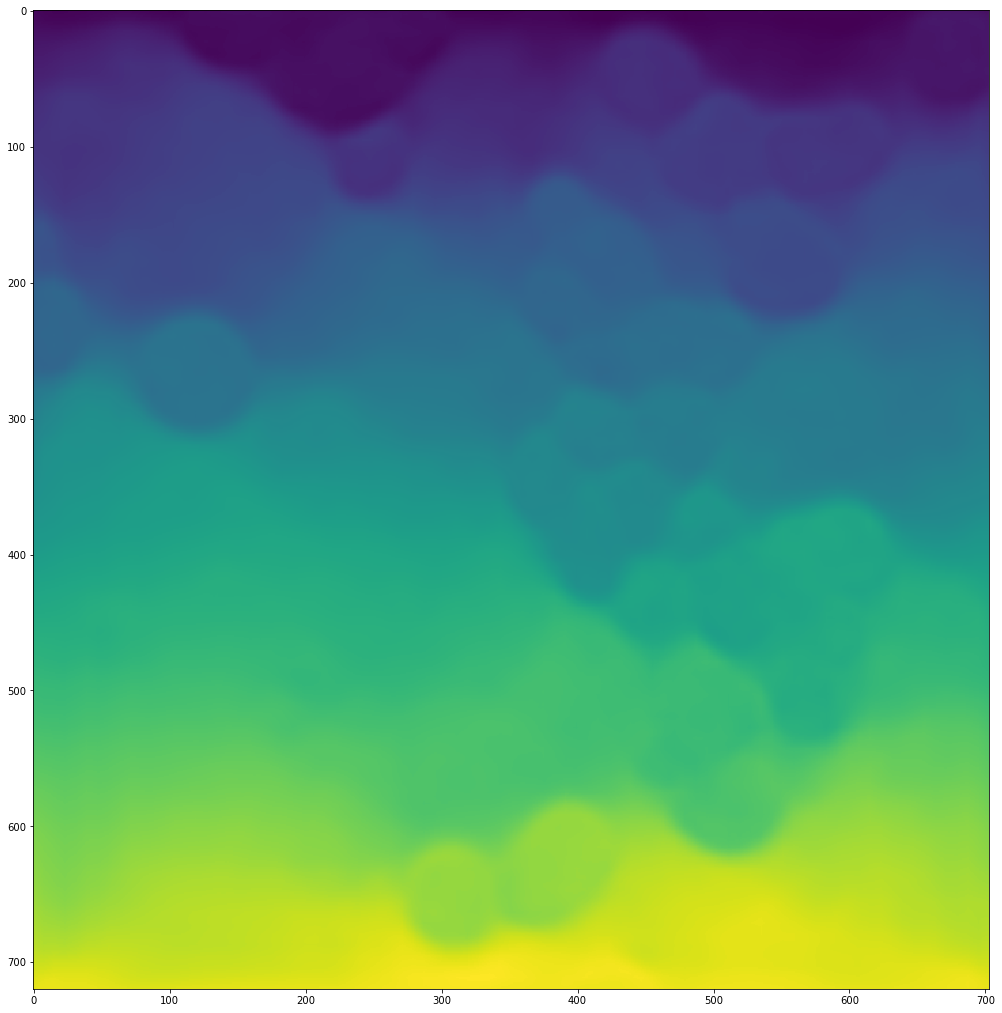

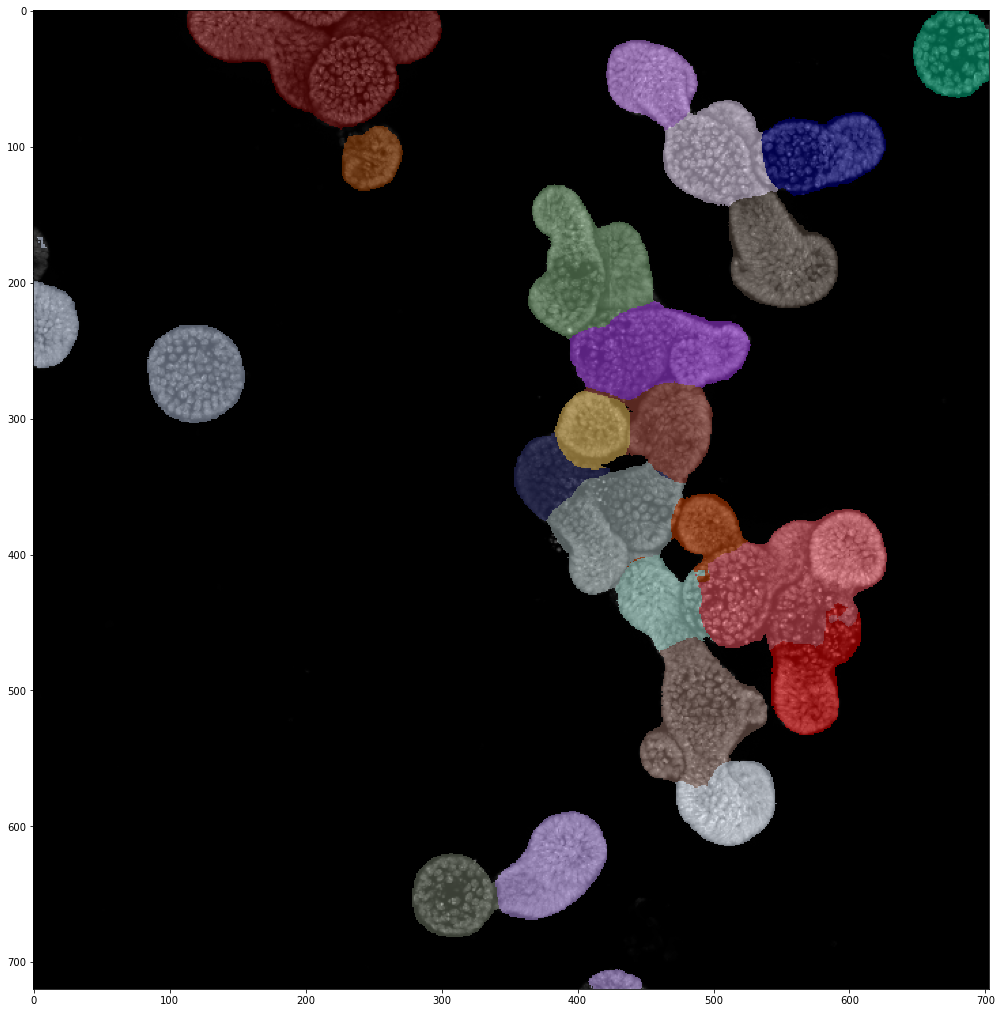

In [6]:
from dlutils.layers.semi_conv import generate_coordinate_grid
from dlutils.postprocessing.voting import embeddings_to_labels

model_fn = model.signatures['model_fun']
img = raw[::4,::4]

img = tf.cast(img, tf.float32)
img = img - tf.reduce_mean(img)
img = img / tf.math.reduce_std(img)

nopostproc = model_fn(tf.convert_to_tensor(img[None, ..., None]))
embeddings = nopostproc['embeddings']
classes = nopostproc['classes']


embeddings = embeddings[0]
fg_mask = classes[0, ..., 1] > 0.5

plt.figure(figsize=(18,18))
plt.imshow(embeddings[..., 0], interpolation='nearest')
plt.show()

# ~with tf.device('/CPU'):
labels = embeddings_to_labels(
    embeddings,
    fg_mask,
    peak_min_distance=2 * 10, 
    spacing=(4*0.322, 4*0.322),
    min_count=2)


plt.figure(figsize=(18,18))
plt.imshow(img, cmap='Greys_r')
plt.imshow(labels, interpolation='nearest', alpha=0.5, cmap='blk_glasbey_hv')
plt.show()